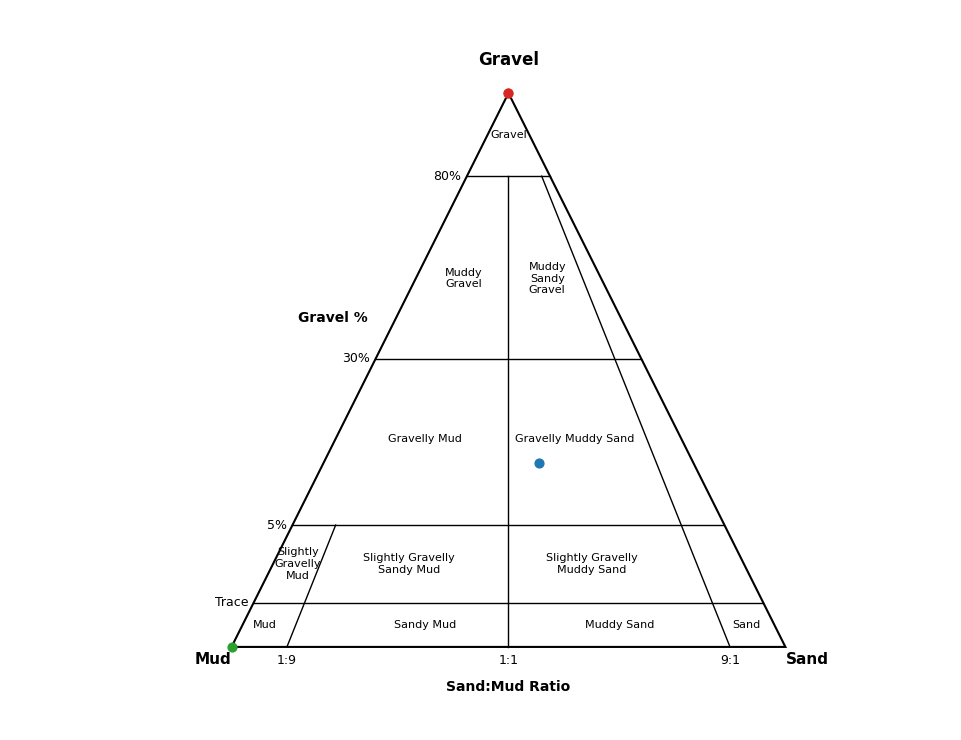

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd

# ==============================
# 1. CARGAR DATOS DESDE EXCEL
# ==============================
ruta_excel = r"C:\Users\usrlabima14\Documents\EDWARD_OSORIO\SEDIMENTOLOGÍA RECIENTE\Muestras.xlsx"  # <-- CAMBIA ESTO

df = pd.read_excel(ruta_excel)

# Normalizar a 100% (por seguridad)
df[['Gravel','Sand','Mud']] = df[['Gravel','Sand','Mud']].div(
    df[['Gravel','Sand','Mud']].sum(axis=1), axis=0
) * 100


# ==============================
# 2. FUNCIONES DE CONVERSIÓN
# ==============================
def to_y(val):
    if val <= 0.01:
        return (val / 0.01) * 8
    elif val <= 5:
        return 8 + (val - 0.01) * (22 - 8) / (5 - 0.01)
    elif val <= 30:
        return 22 + (val - 5) * (52 - 22) / (30 - 5)
    elif val <= 80:
        return 52 + (val - 30) * (85 - 52) / (80 - 30)
    else:
        return 85 + (val - 80) * (100 - 85) / (100 - 80)


def ternary_to_xy(gravel, sand, mud):
    y = to_y(gravel)
    ancho = 100 * (1 - y / 100)
    
    # evitar división por cero
    if (sand + mud) == 0:
        ratio = 0
    else:
        ratio = sand / (sand + mud)
    
    x = (100 - ancho) / 2 + ratio * ancho
    
    return x, y


# ==============================
# 3. FUNCIÓN PRINCIPAL
# ==============================
def draw_folk_with_data(df):
    fig, ax = plt.subplots(figsize=(12, 7.5))
    h_tri = 100 

    # --- Triángulo base ---
    top, left, right = [50, h_tri], [0, 0], [100, 0]
    ax.add_patch(patches.Polygon([left, top, right],
                                 closed=True,
                                 facecolor='white',
                                 edgecolor='black',
                                 linewidth=1.5))

    # --- Líneas horizontales ---
    niveles = [0.01, 5, 30, 80]
    labels = {0.01: 'Trace', 5: '5%', 30: '30%', 80: '80%'}

    for n in niveles:
        y_c = to_y(n)
        ancho = 100 * (1 - y_c/h_tri)
        x_s, x_e = (100 - ancho)/2, 100 - (100 - ancho)/2
        ax.plot([x_s, x_e], [y_c, y_c], color='black', linewidth=1)

        if n in labels:
            ax.text(x_s - 1, y_c, labels[n],
                    ha='right', va='center', fontsize=9)

    # --- Líneas de ratio ---
    def get_x_at_y(x_base, y_target):
        return x_base + (50 - x_base) * (y_target / h_tri)

    # 1:9
    y_lim_19 = to_y(5)
    ax.plot([10, get_x_at_y(10, y_lim_19)], [0, y_lim_19],
            color='black', linewidth=1)

    # 1:1 y 9:1
    for r in [50, 90]:
        y_lim = to_y(80)
        ax.plot([r, get_x_at_y(r, y_lim)], [0, y_lim],
                color='black', linewidth=1)

    # --- Texto interno ---
    s = {'ha': 'center', 'va': 'center', 'fontsize': 8}

    ax.text(50, to_y(90), "Gravel", **s)
    ax.text(42, to_y(52), "Muddy\nGravel", **s)
    ax.text(57, to_y(52), "Muddy\nSandy\nGravel", **s)
    ax.text(35, to_y(18), "Gravelly Mud", **s)
    ax.text(62, to_y(18), "Gravelly Muddy Sand", **s)

    y_sg_text = to_y(2.5)
    ax.text(12, y_sg_text, "Slightly\nGravelly\nMud", **s)
    ax.text(32, y_sg_text, "Slightly Gravelly\nSandy Mud", **s)
    ax.text(65, y_sg_text, "Slightly Gravelly\nMuddy Sand", **s)

    ax.text(6, 4, "Mud", **s)
    ax.text(35, 4, "Sandy Mud", **s)
    ax.text(70, 4, "Muddy Sand", **s)
    ax.text(93, 4, "Sand", **s)

    # --- Ejes ---
    ax.text(50, 105, 'Gravel', ha='center', weight='bold', fontsize=12)
    ax.text(12, to_y(40), 'Gravel %', weight='bold', fontsize=10)
    ax.text(0, -3, 'Mud', ha='right', weight='bold', fontsize=11)
    ax.text(100, -3, 'Sand', ha='left', weight='bold', fontsize=11)
    ax.text(50, -8, 'Sand:Mud Ratio', ha='center', weight='bold', fontsize=10)

    for r, lab in zip([10, 50, 90], ['1:9', '1:1', '9:1']):
        ax.text(r, -3, lab, ha='center', fontsize=9)

    # ==============================
    # 4. PLOT DE DATOS
    # ==============================
    for i, row in df.iterrows():
        x, y = ternary_to_xy(row['Gravel'], row['Sand'], row['Mud'])

        ax.scatter(x, y, s=40, zorder=5)

        # etiqueta opcional
        if 'Sample' in df.columns:
            ax.text(x, y + 1.5, str(row['Sample']),
                    fontsize=7, ha='center')

    # --- Ajustes finales ---
    ax.set_xlim(-40, 130)
    ax.set_ylim(-15, 115)
    ax.set_aspect('equal')
    ax.axis('off')

    plt.tight_layout()
    plt.show()


# ==============================
# 5. EJECUTAR
# ==============================
draw_folk_with_data(df)

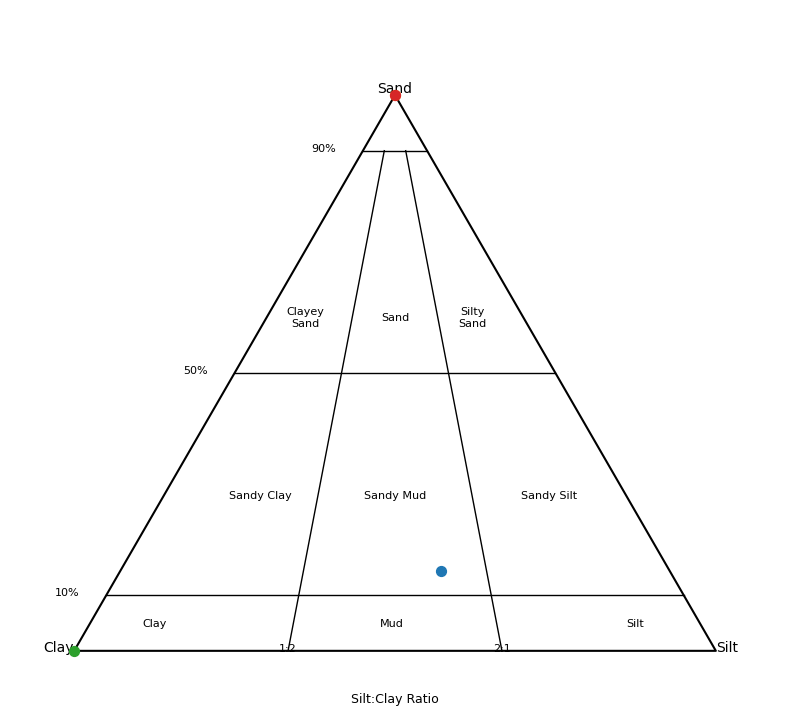

In [71]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================
# 1. CARGAR DATOS
# ==============================
ruta_excel = r"C:\Users\usrlabima14\Documents\EDWARD_OSORIO\SEDIMENTOLOGÍA RECIENTE\Muestras2.xlsx"
df = pd.read_excel(ruta_excel)

# Normalizar a 1
df[['Sand','Silt','Clay']] = df[['Sand','Silt','Clay']].div(
    df[['Sand','Silt','Clay']].sum(axis=1), axis=0
)

# ==============================
# 2. TRANSFORMACIÓN TERNARIA
# ==============================
def ternary_to_xy(sand, silt, clay):
    x = 0.5 * (2*silt + sand)
    y = (np.sqrt(3)/2) * sand
    return x, y

# Función corta tipo "to_xy"
def t(s, si, c):
    return ternary_to_xy(s, si, c)

# ==============================
# 3. DIBUJAR LÍNEAS EN TERNARIO
# ==============================
def plot_ternary_line(ax, sand_vals, silt_vals, clay_vals, **kwargs):
    xs, ys = [], []
    for s, si, c in zip(sand_vals, silt_vals, clay_vals):
        x, y = ternary_to_xy(s, si, c)
        xs.append(x)
        ys.append(y)
    ax.plot(xs, ys, **kwargs)

# ==============================
# 4. DIAGRAMA
# ==============================
def draw_shepard(df):
    fig, ax = plt.subplots(figsize=(8,8))

    # Triángulo base
    corners = [
        t(0,0,1),
        t(0,1,0),
        t(1,0,0),
        t(0,0,1)
    ]
    ax.plot([p[0] for p in corners], [p[1] for p in corners], 'k')

    # ==========================
    # Líneas Sand % (10, 50, 90)
    # ==========================
    for s_val in [0.1, 0.5, 0.9]:
        s_vals = np.full(100, s_val)
        si_vals = np.linspace(0, 1-s_val, 100)
        c_vals = 1 - s_vals - si_vals

        plot_ternary_line(ax, s_vals, si_vals, c_vals, color='black', lw=1)

        # etiqueta %
        x, y = t(s_val, 0, 1-s_val)
        ax.text(x - 0.08, y, f"{int(s_val*100)}%", fontsize=8)

    # ==========================
    # Líneas Silt:Clay (1:2 y 2:1) hasta 90%
    # ==========================
    tt = np.linspace(0, 0.9, 100)

    # 1:2
    sand = tt
    silt = (1 - tt) * (1/3)
    clay = (1 - tt) * (2/3)
    plot_ternary_line(ax, sand, silt, clay, color='black', lw=1)

    # 2:1
    silt = (1 - tt) * (2/3)
    clay = (1 - tt) * (1/3)
    plot_ternary_line(ax, sand, silt, clay, color='black', lw=1)

    # ==========================
    # ETIQUETAS DE CAMPOS (tipo Folk)
    # ==========================
    s = {'ha': 'center', 'va': 'center', 'fontsize': 8}

    # Superior
    ax.text(*t(0.6, 0.2, 0.3), "Sand", **s)

    # Banda superior
    ax.text(*t(0.6, 0.06, 0.3), "Clayey\nSand", **s)
    ax.text(*t(0.6, 0.32, 0.1), "Silty\nSand", **s)

    # Banda media
    ax.text(*t(0.28, 0.15, 0.52), "Sandy Clay", **s)
    ax.text(*t(0.28, 0.36, 0.28), "Sandy Mud", **s)
    ax.text(*t(0.28, 0.6, 0.12), "Sandy Silt", **s)

    # Base
    ax.text(*t(0.05, 0.1, 0.85), "Clay", **s)
    ax.text(*t(0.05, 0.47, 0.55), "Mud", **s)
    ax.text(*t(0.05, 0.85, 0.1), "Silt", **s)

    # ==========================
    # ETIQUETAS EJES
    # ==========================
    ax.text(*t(1,0,0), "Sand", ha='center', va='bottom')
    ax.text(*t(0,1,0), "Silt", ha='left')
    ax.text(*t(0,0,1), "Clay", ha='right')

    ax.text(0.5, -0.08, "Silt:Clay Ratio", ha='center', fontsize=9)
    ax.text(*t(0, 1/3, 2/3), "1:2", fontsize=8, ha='center')
    ax.text(*t(0, 2/3, 1/3), "2:1", fontsize=8, ha='center')

    # ==========================
    # PLOT DE DATOS
    # ==========================
    for _, row in df.iterrows():
        x, y = t(row['Sand'], row['Silt'], row['Clay'])
        ax.scatter(x, y, s=50, zorder=5)

        if 'Sample' in df.columns:
            ax.text(x, y+0.02, row['Sample'], fontsize=7, ha='center')

    # ==========================
    # AJUSTES
    # ==========================
    ax.set_aspect('equal')
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1)
    ax.axis('off')

    plt.tight_layout()
    plt.show()


# ==============================
# 5. EJECUTAR
# ==============================
draw_shepard(df)